# Giai đoạn 2 — Feature Engineering

Notebook này tập trung vào **tạo và kiểm tra feature**:

1. Tải dữ liệu train (có nhãn) để kiểm tra feature.
2. Gọi `add_features()` từ `src/features.py` — logic tái sử dụng được.
3. Kiểm tra shape, dtypes, missing values sau khi tạo feature.
4. Thống kê mô tả và phân phối các feature mới.
5. So sánh phân phối feature giữa giao dịch fraud và non-fraud.
6. Kiểm tra tương quan giữa các feature mới.

> **Không có** model fitting, cross-validation hay tạo submission trong notebook này.
> Các bước đó thuộc về `03_modeling.ipynb`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Thêm thư mục gốc dự án vào sys.path để import src/
PROJECT_ROOT = Path("../").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.features import (
    ENGINEERED_NUMERIC_COLUMNS,
    INTERACTION_COLUMNS,
    RAW_CATEGORICAL_COLUMNS,
    RAW_NUMERIC_COLUMNS,
    add_features,
)

DATA_DIR = PROJECT_ROOT / "data"

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)

## 1. Tải dữ liệu

In [2]:
train_raw = pd.read_csv(DATA_DIR / "train.csv")

target = train_raw["is_fraud"].astype(np.int8)
X_raw = train_raw.drop(columns="is_fraud")

print("Shape train (trước FE):", X_raw.shape)
print(f"Tỷ lệ fraud: {target.mean():.4%}")

Shape train (trước FE): (699960, 25)
Tỷ lệ fraud: 1.6700%


## 2. Tạo feature

Logic tạo feature nằm trong `src/features.py::add_features()`.
Hàm này sẽ được tái sử dụng trong notebook modeling.

In [3]:
X = add_features(X_raw)

print("Shape sau FE:", X.shape)
print(f"Số feature mới thêm: {X.shape[1] - X_raw.shape[1]}")

Shape sau FE: (699960, 42)
Số feature mới thêm: 17


## 3. Kiểm tra schema sau Feature Engineering

In [4]:
print("=== Dtypes ===")
print(X.dtypes.to_string())
print()
print("=== Missing values ===")
missing = X.isna().sum()
print(missing[missing > 0] if missing.any() else "Không có missing values.")

=== Dtypes ===
id                                   int64
amount_usd                         float64
hours_since_last_txn               float64
txn_count_last_24h                   int64
distance_from_home_km              float64
card_age_months                      int64
customer_age                         int64
account_balance_usd                float64
cvv_retry_count                      int64
velocity_score                     float64
time_of_day_hour                     int64
day_of_week                          int64
merchant_risk_score                float64
prior_disputes                       int64
merchant_category                 category
card_type                         category
auth_method                       category
channel                           category
device_type                       category
is_foreign_transaction                bool
is_new_merchant                       bool
used_vpn                              bool
ip_country_mismatch                   b

In [5]:
# Danh sách các feature mới (numeric và interaction)
new_numeric_cols = ENGINEERED_NUMERIC_COLUMNS
interaction_cols = INTERACTION_COLUMNS

print("Feature số mới:", new_numeric_cols)
print()
print("Feature tương tác (categorical):", interaction_cols)

Feature số mới: ['amount_log1p', 'amount_fraction', 'amount_is_integer', 'amount_rounded_5', 'amount_rounded_10', 'hours_since_last_txn_log1p', 'txn_count_last_24h_log1p', 'txn_intensity_per_hour', 'txn_intensity_per_day', 'is_recent_txn', 'is_high_velocity', 'balance_amount_ratio', 'prior_disputes_per_card_age']

Feature tương tác (categorical): ['merchant_category__channel', 'merchant_category__auth_method', 'channel__auth_method', 'device_type__channel']


## 4. Thống kê mô tả các feature số mới

In [6]:
X[new_numeric_cols].describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
amount_log1p,699960.0,3.4557,1.0753,0.6931,2.8220,3.3411,3.7867,8.8355
amount_fraction,699960.0,0.4894,0.2885,0.0000,0.2300,0.4800,0.7400,0.9900
amount_is_integer,699960.0,0.0094,0.0963,0.0000,0.0000,0.0000,0.0000,1.0000
amount_rounded_5,699960.0,0.0015,0.0385,0.0000,0.0000,0.0000,0.0000,1.0000
amount_rounded_10,699960.0,0.0009,0.0306,0.0000,0.0000,0.0000,0.0000,1.0000
hours_since_last_txn_log1p,699960.0,1.7279,0.7952,0.0100,1.1346,1.7457,2.3214,3.9699
txn_count_last_24h_log1p,699960.0,1.3034,0.4172,0.0000,1.0986,1.3863,1.6094,2.4849
txn_intensity_per_hour,699960.0,1.7225,4.9794,0.0000,0.2604,0.5744,1.3598,174.1935
txn_intensity_per_day,699960.0,2.4256,1.3039,0.0000,1.5474,2.3159,3.2182,9.9875
is_recent_txn,699960.0,0.1149,0.3189,0.0000,0.0000,0.0000,0.0000,1.0000


## 5. So sánh phân phối feature giữa fraud và non-fraud

Mục tiêu: nhận biết feature nào có khả năng phân biệt tốt giữa hai lớp.

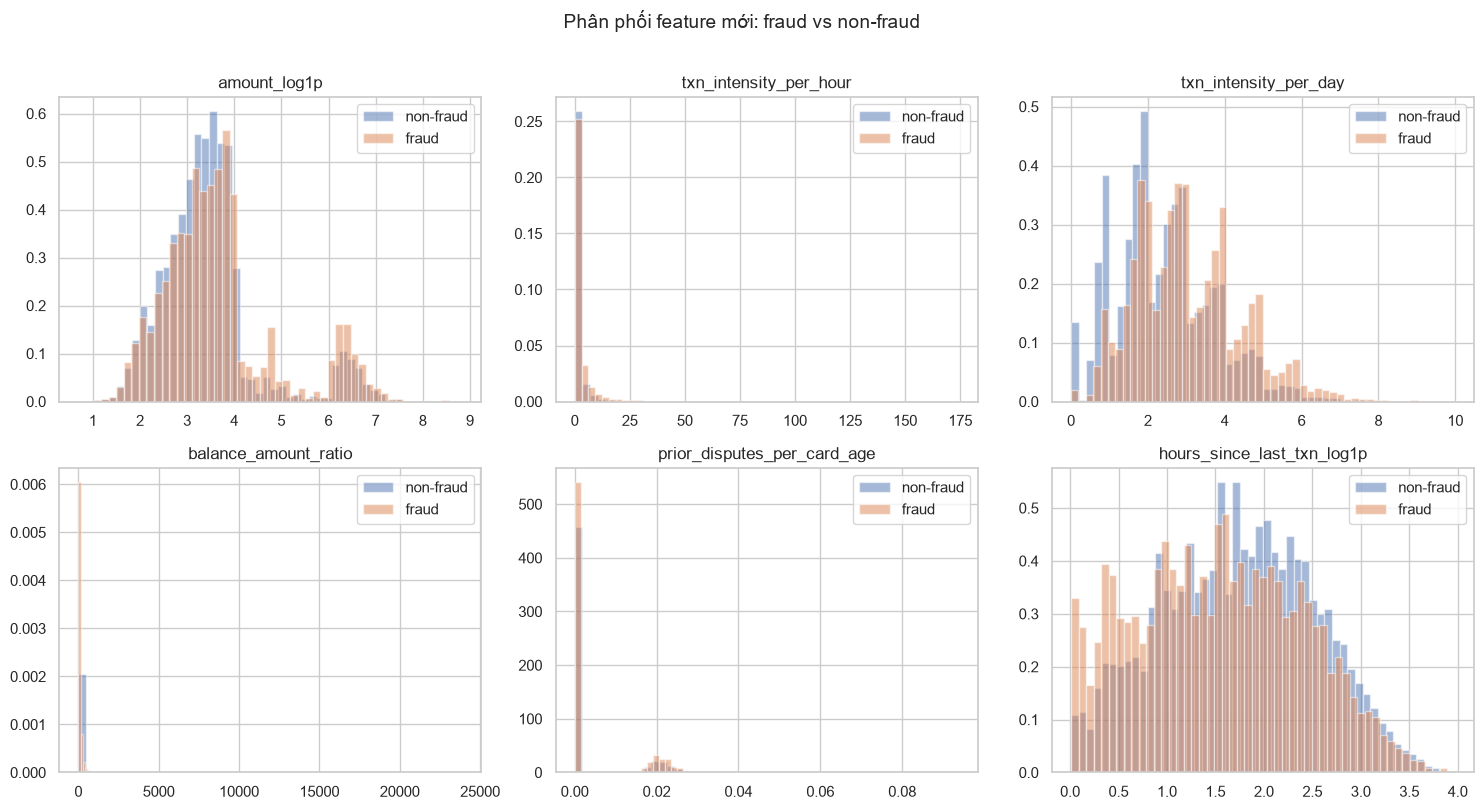

In [7]:
plot_cols = [
    "amount_log1p",
    "txn_intensity_per_hour",
    "txn_intensity_per_day",
    "balance_amount_ratio",
    "prior_disputes_per_card_age",
    "hours_since_last_txn_log1p",
]

X_plot = X[plot_cols].copy()
X_plot["is_fraud"] = target

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, col in zip(axes, plot_cols):
    for label, grp in X_plot.groupby("is_fraud")[col]:
        # Vẽ histogram bằng matplotlib để tránh seaborn KDE lỗi với dữ liệu lớn
        ax.hist(
            grp,
            bins=50,
            density=True,
            alpha=0.5,
            label="fraud" if label == 1 else "non-fraud",
        )
    ax.set_title(col)
    ax.legend()

plt.suptitle("Phân phối feature mới: fraud vs non-fraud", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 6. Kiểm tra các feature nhị phân

In [8]:
binary_cols = [
    "amount_is_integer", "amount_rounded_5", "amount_rounded_10",
    "is_recent_txn", "is_high_velocity",
]

summary_rows = []
for col in binary_cols:
    fraud_rate_0 = target[X[col] == 0].mean()
    fraud_rate_1 = target[X[col] == 1].mean()
    pct_ones = X[col].mean()
    summary_rows.append({
        "feature": col,
        "% value=1": f"{pct_ones:.2%}",
        "fraud_rate (val=0)": f"{fraud_rate_0:.4%}",
        "fraud_rate (val=1)": f"{fraud_rate_1:.4%}",
    })

pd.DataFrame(summary_rows).set_index("feature")

,% value=1,fraud_rate (val=0),fraud_rate (val=1)
feature,,,
amount_is_integer,0.94%,1.6660%,2.0887%
amount_rounded_5,0.15%,1.6703%,1.4451%
amount_rounded_10,0.09%,1.6704%,1.2158%
is_recent_txn,11.49%,1.5036%,2.9512%
is_high_velocity,15.40%,1.4261%,3.0093%


## 7. Kiểm tra các feature tương tác (categorical)

Xem số lượng giá trị unique và top giá trị theo fraud rate.

In [9]:
for col in INTERACTION_COLUMNS:
    n_unique = X[col].nunique()
    top = (
        pd.DataFrame({"feature": X[col], "is_fraud": target})
        .groupby("feature")["is_fraud"]
        .agg(["mean", "count"])
        .rename(columns={"mean": "fraud_rate", "count": "n"})
        .sort_values("fraud_rate", ascending=False)
        .head(5)
    )
    print(f"\n=== {col} | unique={n_unique} ===")
    display(top)


=== merchant_category__channel | unique=60 ===


,fraud_rate,n
feature,,
Gift Cards__In-App,0.078341,1085
Gift Cards__Online,0.075890,3650
Gift Cards__POS,0.075633,2922
Crypto Exchange__POS,0.073510,1510
Crypto Exchange__ATM,0.067568,222



=== merchant_category__auth_method | unique=60 ===


,fraud_rate,n
feature,,
Gift Cards__No Authentication,0.230072,1104
Crypto Exchange__No Authentication,0.223176,466
Gaming__No Authentication,0.190947,2629
Electronics__No Authentication,0.113361,4543
Streaming__No Authentication,0.086847,4744



=== channel__auth_method | unique=25 ===


,fraud_rate,n
feature,,
Contactless__No Authentication,0.065864,10051
ATM__No Authentication,0.065545,2853
Online__No Authentication,0.065294,26036
POS__No Authentication,0.063727,19364
In-App__No Authentication,0.061558,8756



=== device_type__channel | unique=40 ===


,fraud_rate,n
feature,,
Mac__ATM,0.021262,1458
Tablet__ATM,0.020194,1238
Smart Watch__ATM,0.019129,941
ATM Machine__POS,0.019057,6087
Smart Watch__Online,0.018928,8189


## 8. Tương quan giữa các feature số mới và target

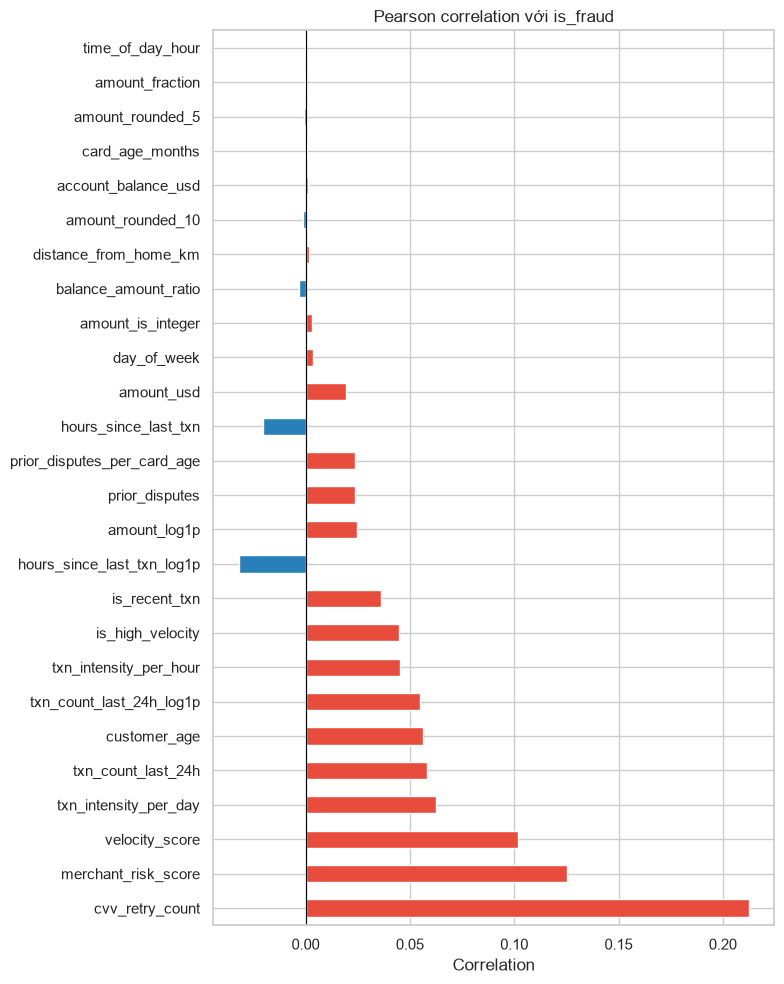

cvv_retry_count                0.2123
merchant_risk_score            0.1254
velocity_score                 0.1016
txn_intensity_per_day          0.0623
txn_count_last_24h             0.0580
customer_age                   0.0561
txn_count_last_24h_log1p       0.0546
txn_intensity_per_hour         0.0453
is_high_velocity               0.0446
is_recent_txn                  0.0360
hours_since_last_txn_log1p    -0.0321
amount_log1p                   0.0246
prior_disputes                 0.0236
prior_disputes_per_card_age    0.0235
hours_since_last_txn          -0.0205
amount_usd                     0.0194
day_of_week                    0.0037
amount_is_integer              0.0032
balance_amount_ratio          -0.0030
distance_from_home_km          0.0018
amount_rounded_10             -0.0011
account_balance_usd            0.0011
card_age_months                0.0007
amount_rounded_5              -0.0007
amount_fraction               -0.0003
time_of_day_hour              -0.0001


In [10]:
all_numeric = RAW_NUMERIC_COLUMNS + ENGINEERED_NUMERIC_COLUMNS
existing_numeric = [c for c in all_numeric if c in X.columns]

corr_with_target = (
    X[existing_numeric]
    .assign(is_fraud=target)
    .corr()["is_fraud"]
    .drop("is_fraud")
    .sort_values(key=abs, ascending=False)
)

fig, ax = plt.subplots(figsize=(8, 10))
corr_with_target.plot.barh(ax=ax, color=corr_with_target.map(lambda v: "#e74c3c" if v > 0 else "#2980b9"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Pearson correlation với is_fraud")
ax.set_xlabel("Correlation")
plt.tight_layout()
plt.show()

print(corr_with_target.round(4).to_string())